# Notebook 01 — FD001 Data Exploration

**Project:** Self-Healing Machines: Predictive Maintenance for a Connected Fleet  
**Dataset:** NASA C-MAPSS, FD001  

## Purpose
Explore the training data, understand engine lifetimes and sensor behavior, construct Remaining Useful Life (RUL) labels, establish a Random Forest baseline, and investigate validation and test-set performance.


In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns",None)
pd.set_option("display.width",150)

In [3]:
columns = (
    ["engine_id","cycle"]
    +[f"setting_{i}" for i in range(1,4)]
    +[f"sensor_{i}" for i in range(1,22)]
) 

print("Number of columns:", len(columns))
print(columns)

Number of columns: 26
['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


In [4]:
from pathlib import Path

def find_project_root():
    current = Path.cwd().resolve()

    for directory in [current, *current.parents]:
        if (directory / "requirements.txt").exists():
            return directory

    raise FileNotFoundError("Project root not found.")

PROJECT_ROOT = find_project_root()

train_path = PROJECT_ROOT / "data" / "raw" / "train" / "train_FD001.txt"

train_df = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None,
    names=columns
)

train_df.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 1. Load and inspect the training data

In [5]:
print("Dataset shape:", train_df.shape)
print("Number of engines:", train_df["engine_id"].nunique())
print("Number of columns:", train_df.shape[1])

Dataset shape: (20631, 26)
Number of engines: 100
Number of columns: 26


In [6]:
display(train_df.head(10))

print("\nData types:")
print(train_df.dtypes)

print("\nDataset information:")
train_df.info()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
5,1,6,-0.0043,-0.0001,100.0,518.67,642.10,1584.47,1398.37,14.62,21.61,554.67,2388.02,9049.68,1.3,47.16,521.68,2388.03,8132.85,8.4108,0.03,391,2388,100.0,38.98,23.3669
6,1,7,0.0010,0.0001,100.0,518.67,642.48,1592.32,1397.77,14.62,21.61,554.34,2388.02,9059.13,1.3,47.36,522.32,2388.03,8132.32,8.3974,0.03,392,2388,100.0,39.10,23.3774
7,1,8,-0.0034,0.0003,100.0,518.67,642.56,1582.96,1400.97,14.62,21.61,553.85,2388.00,9040.80,1.3,47.24,522.47,2388.03,8131.07,8.4076,0.03,391,2388,100.0,38.97,23.3106
8,1,9,0.0008,0.0001,100.0,518.67,642.12,1590.98,1394.80,14.62,21.61,553.69,2388.05,9046.46,1.3,47.29,521.79,2388.05,8125.69,8.3728,0.03,392,2388,100.0,39.05,23.4066
9,1,10,-0.0033,0.0001,100.0,518.67,641.71,1591.24,1400.46,14.62,21.61,553.59,2388.05,9051.70,1.3,47.03,521.79,2388.06,8129.38,8.4286,0.03,393,2388,100.0,38.95,23.4694



Data types:
engine_id      int64
cycle          int64
setting_1    float64
setting_2    float64
setting_3    float64
sensor_1     float64
sensor_2     float64
sensor_3     float64
sensor_4     float64
sensor_5     float64
sensor_6     float64
sensor_7     float64
sensor_8     float64
sensor_9     float64
sensor_10    float64
sensor_11    float64
sensor_12    float64
sensor_13    float64
sensor_14    float64
sensor_15    float64
sensor_16    float64
sensor_17      int64
sensor_18      int64
sensor_19    float64
sensor_20    float64
sensor_21    float64
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   engine_id  20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-n

In [7]:
print(train_df.isnull().sum())
print("\n Duplicate rows:",train_df.duplicated().sum())

engine_id    0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
dtype: int64

 Duplicate rows: 0


## 2. Understand engine lifetimes and sensor behavior

In [8]:
engine_lifetimes =(
    train_df.groupby("engine_id")["cycle"]
    .max()
    .rename("lifetime_cycles")
)
print(engine_lifetimes.describe())

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: lifetime_cycles, dtype: float64


In [9]:
sensor_columns = [f"sensor_{i}" for i in range(1, 22)]

sensor_std = train_df[sensor_columns].std()

print("Sensors with zero standard deviation:")
print(sensor_std[sensor_std == 0])

print("\nSensor standard deviations:")
display(sensor_std.sort_values())

Sensors with zero standard deviation:
sensor_1     0.0
sensor_10    0.0
sensor_18    0.0
sensor_19    0.0
dtype: float64

Sensor standard deviations:


sensor_1     0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    3.469531e-18
sensor_5     5.329200e-15
sensor_6     1.388985e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
sensor_21    1.082509e-01
sensor_20    1.807464e-01
sensor_11    2.670874e-01
sensor_2     5.000533e-01
sensor_12    7.375534e-01
sensor_7     8.850923e-01
sensor_17    1.548763e+00
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_14    1.907618e+01
sensor_9     2.208288e+01
dtype: float64

In [10]:
sensor_columns = [f"sensor_{i}" for i in range(1, 22)]

sensor_analysis = pd.DataFrame({
    "unique_values": train_df[sensor_columns].nunique(),
    "mean": train_df[sensor_columns].mean(),
    "std": train_df[sensor_columns].std(),
    "min": train_df[sensor_columns].min(),
    "max": train_df[sensor_columns].max()
})

display(sensor_analysis)

,unique_values,mean,std,min,max
sensor_1,1,518.670000,0.000000e+00,518.6700,518.6700
sensor_2,310,642.680934,5.000533e-01,641.2100,644.5300
sensor_3,3012,1590.523119,6.131150e+00,1571.0400,1616.9100
sensor_4,4051,1408.933782,9.000605e+00,1382.2500,1441.4900
sensor_5,1,14.620000,5.329200e-15,14.6200,14.6200
sensor_6,2,21.609803,1.388985e-03,21.6000,21.6100
sensor_7,513,553.367711,8.850923e-01,549.8500,556.0600
sensor_8,53,2388.096652,7.098548e-02,2387.9000,2388.5600
sensor_9,6403,9065.242941,2.208288e+01,9021.7300,9244.5900
sensor_10,1,1.300000,0.000000e+00,1.3000,1.3000


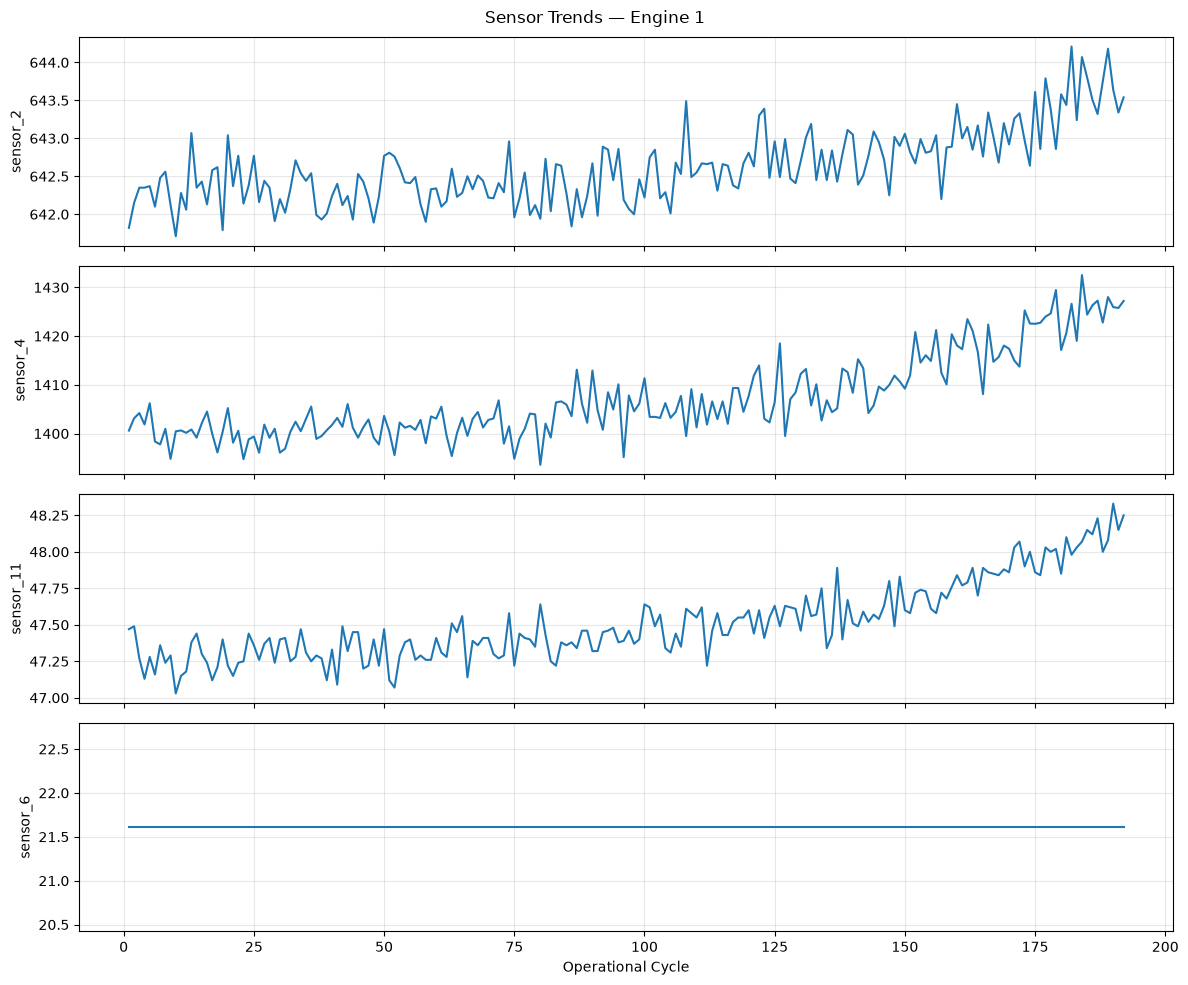

In [56]:
engine_id = 1

engine_data = (
    train_df[train_df["engine_id"] == engine_id]
    .sort_values("cycle")
)

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

for ax, sensor in zip(axes, ["sensor_2", "sensor_4", "sensor_11","sensor_6"]):
    ax.plot(engine_data["cycle"], engine_data[sensor])
    ax.set_ylabel(sensor)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Operational Cycle")

fig.suptitle(f"Sensor Trends — Engine {engine_id}")
plt.tight_layout()
plt.show()

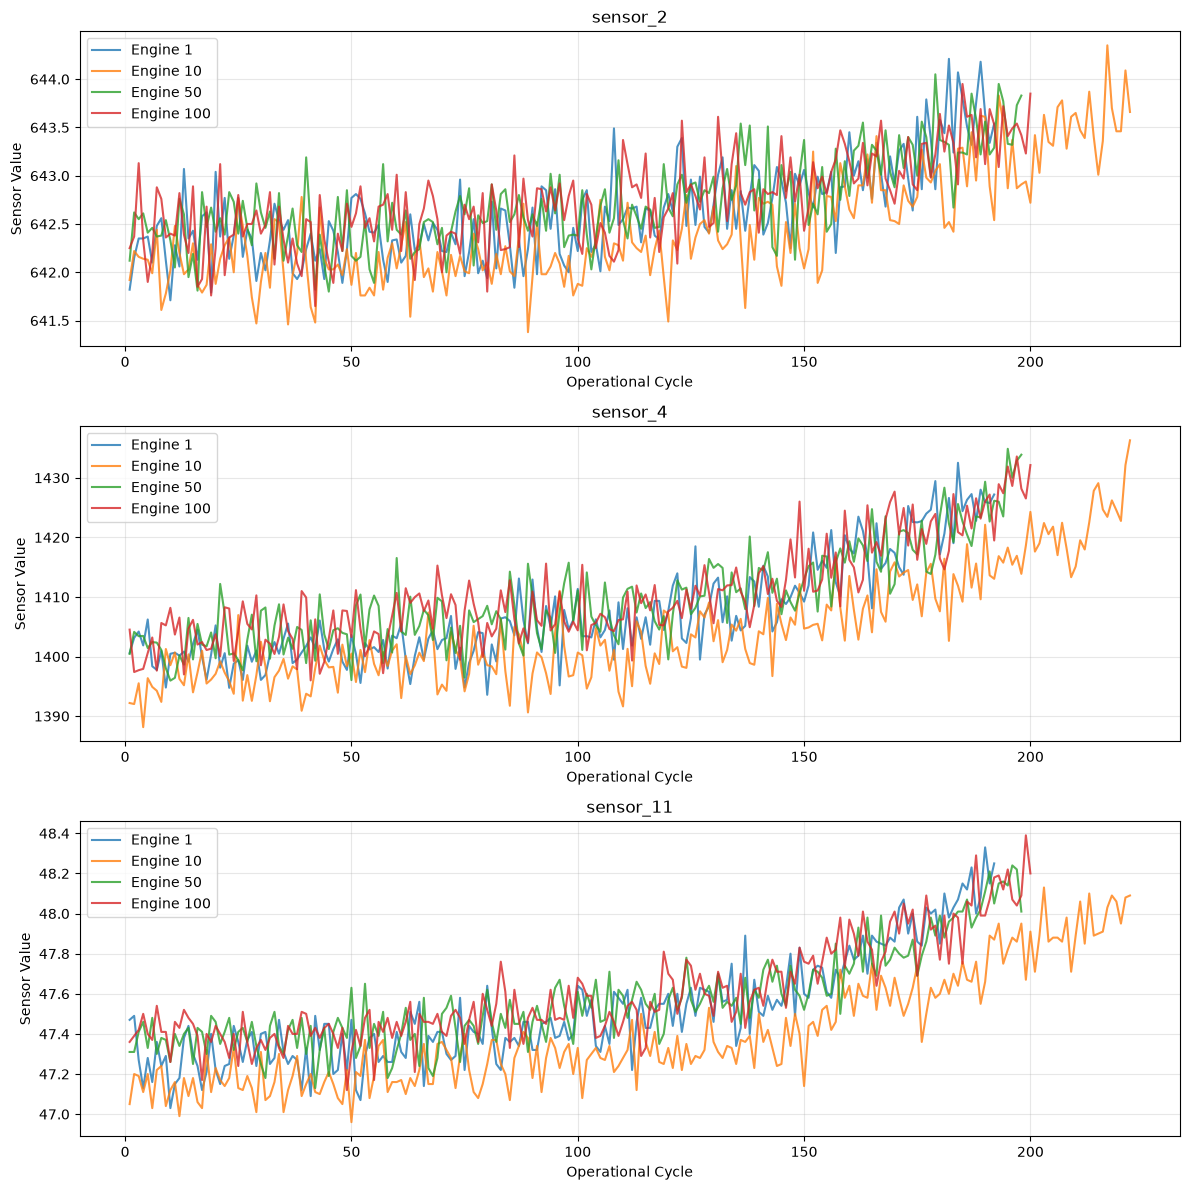

In [12]:
engines = [1, 10, 50, 100]
sensors = ["sensor_2", "sensor_4", "sensor_11"]

fig, axes = plt.subplots(
    len(sensors),
    1,
    figsize=(12, 12)
)

for ax, sensor in zip(axes, sensors):
    for engine_id in engines:
        engine_data = train_df[
            train_df["engine_id"] == engine_id
        ]

        ax.plot(
            engine_data["cycle"],
            engine_data[sensor],
            label=f"Engine {engine_id}",
            alpha=0.8
        )

    ax.set_title(sensor)
    ax.set_xlabel("Operational Cycle")
    ax.set_ylabel("Sensor Value")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Construct Remaining Useful Life (RUL) labels

In [13]:
# Find the final recorded cycle for each engine
max_cycles = (
    train_df.groupby("engine_id")["cycle"]
    .max()
    .rename("max_cycle")
)

# Attach each engine's maximum cycle to its observations
train_df = train_df.merge(
    max_cycles,
    on="engine_id",
    how="left"
)

# Calculate Remaining Useful Life
train_df["RUL"] = train_df["max_cycle"] - train_df["cycle"]

# Inspect the generated labels
display(
    train_df[
        ["engine_id", "cycle", "max_cycle", "RUL"]
    ].head(10)
)

,engine_id,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


In [14]:
print("Minimum RUL:", train_df["RUL"].min())
print("Maximum RUL:", train_df["RUL"].max())

print("\nLast observation for each engine:")
display(
    train_df.groupby("engine_id")
    .tail(1)[["engine_id", "cycle", "RUL"]]
    .head(10)
)

Minimum RUL: 0
Maximum RUL: 361

Last observation for each engine:


,engine_id,cycle,RUL
191,1,192,0
478,2,287,0
657,3,179,0
846,4,189,0
1115,5,269,0
1303,6,188,0
1562,7,259,0
1712,8,150,0
1913,9,201,0
2135,10,222,0


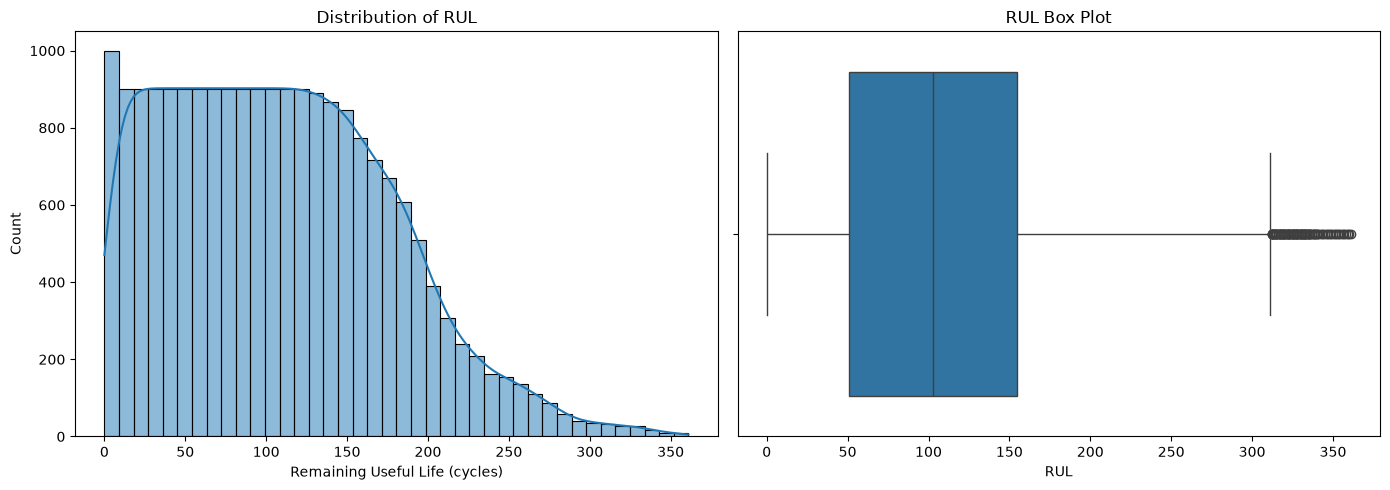

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=train_df,
    x="RUL",
    bins=40,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of RUL")
axes[0].set_xlabel("Remaining Useful Life (cycles)")

sns.boxplot(
    data=train_df,
    x="RUL",
    ax=axes[1]
)
axes[1].set_title("RUL Box Plot")

plt.tight_layout()
plt.show()

## 4. Explore capped RUL targets

In [16]:
RUL_CAP = 125

train_df["RUL_capped"] = train_df["RUL"].clip(upper=RUL_CAP)

display(
    train_df[
        ["engine_id", "cycle", "RUL", "RUL_capped"]
    ].sample(10, random_state=42)
)

,engine_id,cycle,RUL,RUL_capped
13857,69,227,135,125
1710,8,148,2,2
9278,48,14,217,125
10786,54,257,0,0
19709,96,158,178,125
15683,78,161,70,70
5377,27,69,87,87
7738,40,101,87,87
5391,27,83,73,73
18302,90,77,77,77


In [17]:
print("Total observations:", len(train_df))

print(
    "Observations affected by capping:",
    (train_df["RUL"] > RUL_CAP).sum()
)

print(
    "Percentage affected:",
    round((train_df["RUL"] > RUL_CAP).mean() * 100, 2),
    "%"
)

Total observations: 20631
Observations affected by capping: 8031
Percentage affected: 38.93 %


## 5. Select features and split by engine

In [18]:
# Identify columns that are constant across the training data
constant_columns = [
    col for col in train_df.columns
    if train_df[col].nunique() == 1
]

print("Constant columns:", constant_columns)

# Keep operational cycle, operating settings, and non-constant sensors
excluded_columns = {
    "engine_id",
    "max_cycle",
    "RUL",
    "RUL_capped"
}

feature_columns = [
    col for col in train_df.columns
    if col not in excluded_columns
    and col not in constant_columns
]

X = train_df[feature_columns]
y_raw = train_df["RUL"]
y_capped = train_df["RUL_capped"]

print("\nNumber of features:", len(feature_columns))
print("Feature columns:", feature_columns)
print("Feature matrix shape:", X.shape)
print("Raw target shape:", y_raw.shape)
print("Capped target shape:", y_capped.shape)

Constant columns: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

Number of features: 18
Feature columns: ['cycle', 'setting_1', 'setting_2', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Feature matrix shape: (20631, 18)
Raw target shape: (20631,)
Capped target shape: (20631,)


In [19]:
from sklearn.model_selection import train_test_split

# Get unique engine IDs
engine_ids = train_df["engine_id"].unique()

# Split engines: 80% training, 20% validation
train_engines, val_engines = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

# Create masks
train_mask = train_df["engine_id"].isin(train_engines)
val_mask = train_df["engine_id"].isin(val_engines)

# Split features
X_train = X.loc[train_mask]
X_val = X.loc[val_mask]

# Split raw RUL targets
y_train_raw = y_raw.loc[train_mask]
y_val_raw = y_raw.loc[val_mask]

# Split capped RUL targets
y_train_capped = y_capped.loc[train_mask]
y_val_capped = y_capped.loc[val_mask]

print("Training engines:", len(train_engines))
print("Validation engines:", len(val_engines))

print("Training observations:", len(X_train))
print("Validation observations:", len(X_val))

print("Engine overlap:", set(train_engines) & set(val_engines))

Training engines: 80
Validation engines: 20
Training observations: 16561
Validation observations: 4070
Engine overlap: set()


## 6. Train the Random Forest baseline

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

rf_raw = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

rf_raw.fit(X_train, y_train_raw)

y_pred_raw = rf_raw.predict(X_val)

mae_raw = mean_absolute_error(y_val_raw, y_pred_raw)
rmse_raw = np.sqrt(mean_squared_error(y_val_raw, y_pred_raw))

print(f"Raw RUL MAE:  {mae_raw:.2f} cycles")
print(f"Raw RUL RMSE: {rmse_raw:.2f} cycles")

Raw RUL MAE:  23.83 cycles
Raw RUL RMSE: 31.39 cycles


In [21]:
rf_capped = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

rf_capped.fit(X_train, y_train_capped)

y_pred_capped = rf_capped.predict(X_val)

mae_capped = mean_absolute_error(y_val_capped, y_pred_capped)
rmse_capped = np.sqrt(mean_squared_error(y_val_capped, y_pred_capped))

print(f"Capped RUL MAE:  {mae_capped:.2f} cycles")
print(f"Capped RUL RMSE: {rmse_capped:.2f} cycles")

Capped RUL MAE:  10.81 cycles
Capped RUL RMSE: 15.97 cycles


In [22]:
results = pd.DataFrame({
    "Target": ["Raw RUL", "Capped RUL"],
    "MAE": [mae_raw, mae_capped],
    "RMSE": [rmse_raw, rmse_capped]
})

display(results)

,Target,MAE,RMSE
0,Raw RUL,23.832730,31.394413
1,Capped RUL,10.812568,15.968963


## 7. Row-level validation and error analysis

Row-level metrics are useful for exploration, but they do not directly match the benchmark task, which evaluates one prediction for each test engine at its final observed cycle.

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Evaluate both models against actual, uncapped RUL
raw_mae = mean_absolute_error(y_val_raw, y_pred_raw)
raw_rmse = np.sqrt(mean_squared_error(y_val_raw, y_pred_raw))

capped_vs_raw_mae = mean_absolute_error(
    y_val_raw,
    y_pred_capped
)

capped_vs_raw_rmse = np.sqrt(
    mean_squared_error(y_val_raw, y_pred_capped)
)

comparison = pd.DataFrame({
    "Model": ["Raw RUL", "Capped RUL"],
    "MAE_vs_actual_RUL": [raw_mae, capped_vs_raw_mae],
    "RMSE_vs_actual_RUL": [raw_rmse, capped_vs_raw_rmse]
})

display(comparison)

,Model,MAE_vs_actual_RUL,RMSE_vs_actual_RUL
0,Raw RUL,23.832730,31.394413
1,Capped RUL,29.999055,43.120190


In [24]:
error_analysis = X_val[["cycle"]].copy()

error_analysis["engine_id"] = train_df.loc[X_val.index, "engine_id"]
error_analysis["actual_RUL"] = y_val_raw
error_analysis["predicted_RUL"] = y_pred_raw

error_analysis["error"] = (
    error_analysis["predicted_RUL"] - error_analysis["actual_RUL"]
)

error_analysis["absolute_error"] = error_analysis["error"].abs()

display(
    error_analysis.sort_values(
        "absolute_error",
        ascending=False
    ).head(15)
)

,cycle,engine_id,actual_RUL,predicted_RUL,error,absolute_error
18417,38,91,97,196.621804,99.621804,99.621804
16995,111,84,156,63.729636,-92.270364,92.270364
8650,14,45,144,233.051482,89.051482,89.051482
16985,101,84,166,78.521419,-87.478581,87.478581
17000,116,84,151,64.640917,-86.359083,86.359083
8681,45,45,113,197.815500,84.815500,84.815500
8649,13,45,145,229.189009,84.189009,84.189009
8646,10,45,148,232.178820,84.178820,84.178820
16982,98,84,169,85.516867,-83.483133,83.483133
16979,95,84,172,88.644458,-83.355542,83.355542


In [25]:
# Collect validation predictions
validation_results = X_val[["cycle"]].copy()

validation_results["engine_id"] = train_df.loc[
    X_val.index, "engine_id"
]

validation_results["actual_RUL"] = y_val_raw
validation_results["predicted_RUL"] = y_pred_raw

# Keep only the final observed cycle of each validation engine
final_cycle_results = (
    validation_results
    .sort_values("cycle")
    .groupby("engine_id")
    .tail(1)
    .copy()
)

final_cycle_results["absolute_error"] = (
    final_cycle_results["actual_RUL"]
    - final_cycle_results["predicted_RUL"]
).abs()

print("Validation engines:", len(final_cycle_results))

print(
    "Final-cycle MAE:",
    round(final_cycle_results["absolute_error"].mean(), 2)
)

print("\nPredictions for each validation engine:")

display(
    final_cycle_results.sort_values("engine_id")
)

Validation engines: 20
Final-cycle MAE: 3.41

Predictions for each validation engine:


,cycle,engine_id,actual_RUL,predicted_RUL,absolute_error
191,192,1,0,6.123018,6.123018
1115,269,5,0,3.323226,3.323226
2375,240,11,0,2.872552,2.872552
2708,163,13,0,1.821417,1.821417
3933,158,19,0,1.430827,1.430827
4732,168,23,0,2.758387,2.758387
6220,234,31,0,7.214718,7.214718
6411,191,32,0,1.836095,1.836095
6806,195,34,0,3.373071,3.373071
7825,188,40,0,2.477065,2.477065


### Superseded experiment — incorrect validation subset

The following historical cell uses `train_mask` when simulating validation engines. It is retained only as an experiment record; do **not** use its output. The corrected held-out-engine evaluation is in the next cell.

In [26]:
# Simulate engines observed before failure.
# Keep validation engines separate from training engines.

validation_simulated = train_df[train_mask].copy()

# Select the final 20% of each validation engine's trajectory to hide.
validation_simulated["max_cycle"] = (
    validation_simulated.groupby("engine_id")["cycle"].transform("max")
)

validation_simulated["cutoff_cycle"] = (
    validation_simulated["max_cycle"] * 0.8
).astype(int)

validation_observed = validation_simulated[
    validation_simulated["cycle"] <= validation_simulated["cutoff_cycle"]
].copy()

# The true RUL at the cutoff is the number of cycles remaining until failure.
validation_observed["true_RUL"] = (
    validation_observed["max_cycle"] - validation_observed["cycle"]
)

# Keep only each engine's last observed cycle.
validation_final = (
    validation_observed.sort_values("cycle")
    .groupby("engine_id")
    .tail(1)
)

display(
    validation_final[
        ["engine_id", "cycle", "max_cycle", "true_RUL"]
    ]
)

,engine_id,cycle,max_cycle,true_RUL
7611,39,102,128,26
14101,70,109,137,28
11363,57,109,137,28
11508,58,117,147,30
4849,24,117,147,30
...,...,...,...,...
16825,83,234,293,59
13368,67,250,313,63
19819,96,268,336,68
18786,92,272,341,69


## 8. Simulated validation at a partial engine lifetime

The evaluation below uses held-out validation engines and predicts RUL at a specified observation cutoff. This is closer to the intended prediction setting than evaluating every row.

In [27]:
# Use only the held-out validation engines
val_trajectories = train_df.loc[val_mask].copy()

# Find each validation engine's actual failure cycle
engine_max = (
    val_trajectories.groupby("engine_id")["cycle"]
    .max()
    .rename("failure_cycle")
)

val_trajectories = val_trajectories.join(
    engine_max, on="engine_id"
)

# Simulate observing only the first 80% of each engine's life
val_trajectories["cutoff_cycle"] = (
    val_trajectories["failure_cycle"] * 0.8
).astype(int)

# Keep observations up to the cutoff
observed_prefix = val_trajectories[
    val_trajectories["cycle"] <= val_trajectories["cutoff_cycle"]
].copy()

# Select one final observed row per engine
val_final = (
    observed_prefix.sort_values("cycle")
    .groupby("engine_id")
    .tail(1)
    .copy()
)

# Calculate ground-truth RUL for evaluation only
val_final["true_RUL"] = (
    val_final["failure_cycle"] - val_final["cycle"]
)

# Predict using only the selected model features
X_val_final = val_final[feature_columns]
val_final["predicted_RUL"] = rf_raw.predict(X_val_final)

# Calculate errors
val_final["absolute_error"] = (
    val_final["true_RUL"] - val_final["predicted_RUL"]
).abs()

print("Number of validation engines:", val_final["engine_id"].nunique())
print("MAE:", mean_absolute_error(
    val_final["true_RUL"], val_final["predicted_RUL"]
))
print("RMSE:", np.sqrt(mean_squared_error(
    val_final["true_RUL"], val_final["predicted_RUL"]
)))

val_final[
    ["engine_id", "cycle", "true_RUL",
     "predicted_RUL", "absolute_error"]
].sort_values("engine_id")

Number of validation engines: 20
MAE: 13.792901623376622
RMSE: 17.220413508341245


,engine_id,cycle,true_RUL,predicted_RUL,absolute_error
152,1,153,39,52.873810,13.873810
1061,5,215,54,54.775899,0.775899
2327,11,192,48,67.196435,19.196435
2675,13,130,33,37.593405,4.593405
3901,19,126,32,43.029220,11.029220
4698,23,134,34,45.567512,11.567512
6173,31,187,47,80.942175,33.942175
6372,32,152,39,45.416103,6.416103
6767,34,156,39,36.137188,2.862812
7787,40,150,38,30.813044,7.186956


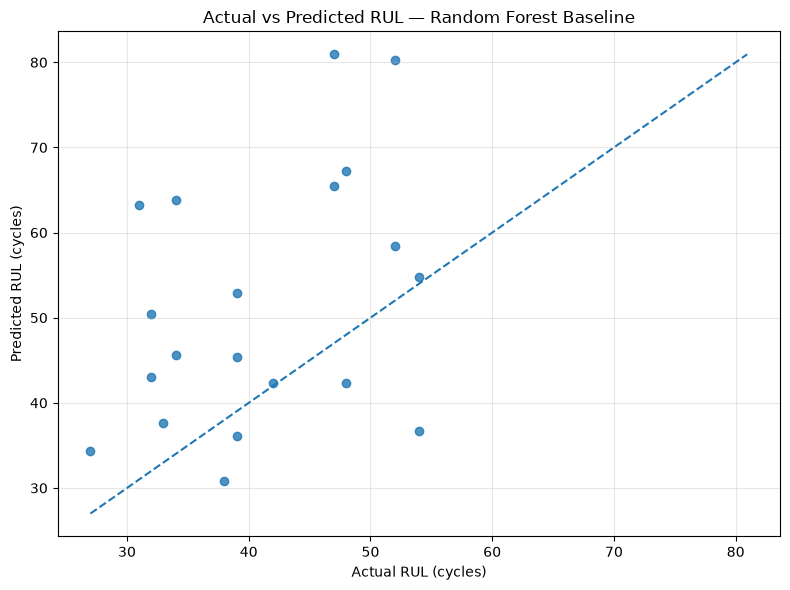

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    val_final["true_RUL"],
    val_final["predicted_RUL"],
    alpha=0.8
)

# Perfect prediction reference line
min_rul = min(
    val_final["true_RUL"].min(),
    val_final["predicted_RUL"].min()
)

max_rul = max(
    val_final["true_RUL"].max(),
    val_final["predicted_RUL"].max()
)

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Actual vs Predicted RUL — Random Forest Baseline")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
error_analysis = val_final[
    [
        "engine_id",
        "cycle",
        "true_RUL",
        "predicted_RUL",
        "absolute_error"
    ]
].copy()

error_analysis["signed_error"] = (
    error_analysis["predicted_RUL"]
    - error_analysis["true_RUL"]
)

print("Largest prediction errors:")
display(
    error_analysis.sort_values(
        "absolute_error",
        ascending=False
    ).head(5)
)

print(
    "\nMean signed error:",
    round(error_analysis["signed_error"].mean(), 2)
)

Largest prediction errors:


,engine_id,cycle,true_RUL,predicted_RUL,absolute_error,signed_error
6173,31,187,47,80.942175,33.942175,33.942175
15491,77,123,31,63.263417,32.263417,32.263417
14895,74,132,34,63.824970,29.824970,29.824970
8998,46,204,52,80.330641,28.330641,28.330641
2327,11,192,48,67.196435,19.196435,19.196435



Mean signed error: 10.49


## 9. Baseline comparison and feature importance

In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Simple baseline: predict the median training RUL for every engine
baseline_prediction = np.full(
    len(val_final),
    y_train_raw.median()
)

baseline_mae = mean_absolute_error(
    val_final["true_RUL"],
    baseline_prediction
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        val_final["true_RUL"],
        baseline_prediction
    )
)

# Current Random Forest performance
rf_mae = mean_absolute_error(
    val_final["true_RUL"],
    val_final["predicted_RUL"]
)

rf_rmse = np.sqrt(
    mean_squared_error(
        val_final["true_RUL"],
        val_final["predicted_RUL"]
    )
)

comparison = pd.DataFrame({
    "Model": [
        "Median RUL Baseline",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        rf_rmse
    ]
})

display(comparison.round(2))

,Model,MAE,RMSE
0,Median RUL Baseline,61.90,62.46
1,Random Forest,13.79,17.22


,feature,importance
0,cycle,0.546933
10,sensor_11,0.143107
9,sensor_9,0.045434
5,sensor_4,0.031995
13,sensor_14,0.029257
11,sensor_12,0.027470
7,sensor_7,0.022872
14,sensor_15,0.022346
17,sensor_21,0.019856
4,sensor_3,0.018998


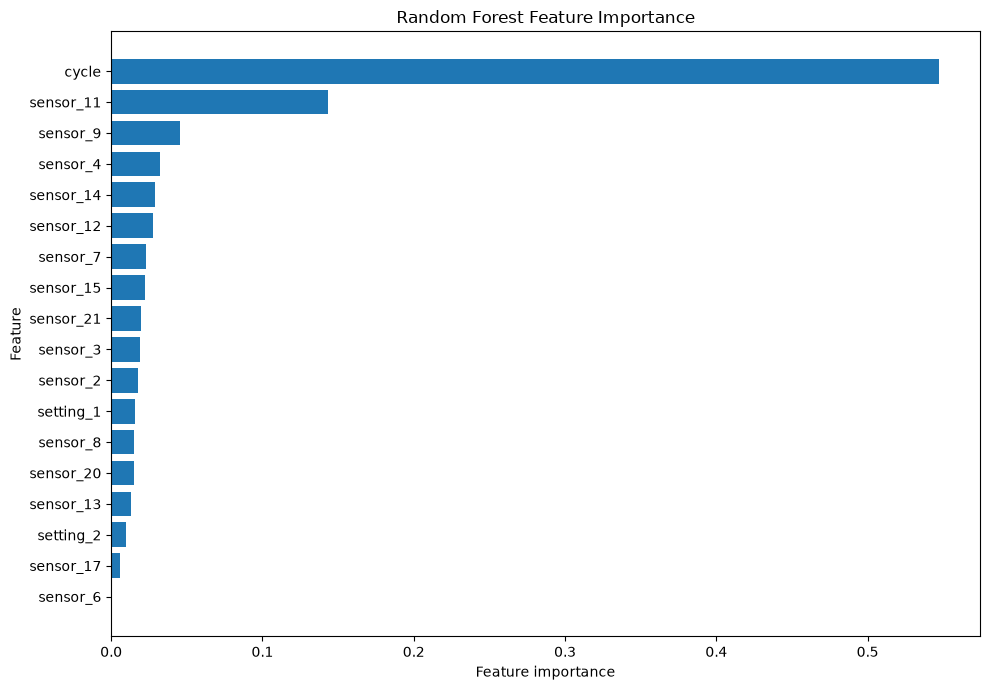

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": rf_raw.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

display(feature_importance)

plt.figure(figsize=(10, 7))

plt.barh(
    feature_importance["feature"].iloc[::-1],
    feature_importance["importance"].iloc[::-1]
)

plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

## 10. Temporal sensor feature experiments

The first feature-engineering attempt below uses backward filling and is **superseded** because it can use later observations to fill earlier rows. Use the next chronological implementation instead.

In [32]:
# Work on a separate copy so we preserve the original dataset
temporal_df = train_df.copy()

sensors_to_engineer = ["sensor_11", "sensor_9"]

# Sort chronologically within each engine
temporal_df = temporal_df.sort_values(
    ["engine_id", "cycle"]
).copy()

for sensor in sensors_to_engineer:

    # Rolling mean over the current and previous 4 cycles
    temporal_df[f"{sensor}_rolling_mean_5"] = (
        temporal_df.groupby("engine_id")[sensor]
        .transform(
            lambda s: s.rolling(
                window=5,
                min_periods=1
            ).mean()
        )
    )

    # Rolling standard deviation over the last 5 cycles
    temporal_df[f"{sensor}_rolling_std_5"] = (
        temporal_df.groupby("engine_id")[sensor]
        .transform(
            lambda s: s.rolling(
                window=5,
                min_periods=2
            ).std()
        )
    )

    # Change from 5 cycles earlier
    temporal_df[f"{sensor}_change_5"] = (
        temporal_df.groupby("engine_id")[sensor]
        .diff(5)
    )

# Fill undefined temporal features at the start of each trajectory
new_temporal_features = [
    f"{sensor}_{suffix}"
    for sensor in sensors_to_engineer
    for suffix in [
        "rolling_mean_5",
        "rolling_std_5",
        "change_5"
    ]
]

temporal_df[new_temporal_features] = (
    temporal_df.groupby("engine_id")[new_temporal_features]
    .transform(lambda group: group.bfill())
)

# For the first rows of an engine, some differences may still be undefined.
temporal_df[new_temporal_features] = (
    temporal_df[new_temporal_features].fillna(0)
)

display(
    temporal_df[
        [
            "engine_id",
            "cycle",
            "sensor_11",
            "sensor_11_rolling_mean_5",
            "sensor_11_rolling_std_5",
            "sensor_11_change_5",
            "sensor_9",
            "sensor_9_rolling_mean_5",
            "sensor_9_rolling_std_5",
            "sensor_9_change_5"
        ]
    ].head(10)
)

,engine_id,cycle,sensor_11,sensor_11_rolling_mean_5,sensor_11_rolling_std_5,sensor_11_change_5,sensor_9,sensor_9_rolling_mean_5,sensor_9_rolling_std_5,sensor_9_change_5
0,1,1,47.47,47.470,0.014142,-0.31,9046.19,9046.190000,1.499066,3.49
1,1,2,47.49,47.480,0.014142,-0.31,9044.07,9045.130000,1.499066,3.49
2,1,3,47.27,47.410,0.121655,-0.31,9052.94,9047.733333,4.632023,3.49
3,1,4,47.13,47.340,0.171659,-0.31,9049.48,9048.170000,3.881555,3.49
4,1,5,47.28,47.328,0.151063,-0.31,9055.15,9049.566000,4.587366,3.49
5,1,6,47.16,47.266,0.141527,-0.31,9049.68,9050.264000,4.193904,3.49
6,1,7,47.36,47.240,0.094074,-0.13,9059.13,9053.276000,4.038407,15.06
7,1,8,47.24,47.234,0.092628,-0.03,9040.80,9050.848000,6.915502,-12.14
8,1,9,47.29,47.266,0.073348,0.16,9046.46,9050.244000,7.191240,-3.02
9,1,10,47.03,47.216,0.127004,-0.25,9051.70,9049.554000,6.755115,-3.45


### Corrected temporal features (chronological rolling statistics and differences)

In [33]:
# Recreate the temporal features without backward filling
temporal_df = train_df.sort_values(
    ["engine_id", "cycle"]
).copy()

for sensor in sensors_to_engineer:

    grouped_sensor = temporal_df.groupby("engine_id")[sensor]

    temporal_df[f"{sensor}_rolling_mean_5"] = (
        grouped_sensor.transform(
            lambda s: s.rolling(5, min_periods=1).mean()
        )
    )

    temporal_df[f"{sensor}_rolling_std_5"] = (
        grouped_sensor.transform(
            lambda s: s.rolling(5, min_periods=2).std()
        )
    )

    temporal_df[f"{sensor}_change_5"] = (
        grouped_sensor.diff(5)
    )

new_temporal_features = [
    f"{sensor}_{suffix}"
    for sensor in sensors_to_engineer
    for suffix in [
        "rolling_mean_5",
        "rolling_std_5",
        "change_5"
    ]
]

# No future information is used to fill missing values
temporal_df[new_temporal_features] = (
    temporal_df[new_temporal_features].fillna(0)
)

display(
    temporal_df[
        ["engine_id", "cycle"] + new_temporal_features
    ].head(10)
)

,engine_id,cycle,sensor_11_rolling_mean_5,sensor_11_rolling_std_5,sensor_11_change_5,sensor_9_rolling_mean_5,sensor_9_rolling_std_5,sensor_9_change_5
0,1,1,47.470,0.000000,0.00,9046.190000,0.000000,0.00
1,1,2,47.480,0.014142,0.00,9045.130000,1.499066,0.00
2,1,3,47.410,0.121655,0.00,9047.733333,4.632023,0.00
3,1,4,47.340,0.171659,0.00,9048.170000,3.881555,0.00
4,1,5,47.328,0.151063,0.00,9049.566000,4.587366,0.00
5,1,6,47.266,0.141527,-0.31,9050.264000,4.193904,3.49
6,1,7,47.240,0.094074,-0.13,9053.276000,4.038407,15.06
7,1,8,47.234,0.092628,-0.03,9050.848000,6.915502,-12.14
8,1,9,47.266,0.073348,0.16,9050.244000,7.191240,-3.02
9,1,10,47.216,0.127004,-0.25,9049.554000,6.755115,-3.45


In [34]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Original features + six temporal features
enhanced_feature_columns = feature_columns + new_temporal_features

X_enhanced = temporal_df[enhanced_feature_columns]
y_enhanced = temporal_df["RUL"]

# Preserve the original engine-level train/validation split
train_mask_enhanced = temporal_df["engine_id"].isin(train_engines)
val_mask_enhanced = temporal_df["engine_id"].isin(val_engines)

X_train_enhanced = X_enhanced.loc[train_mask_enhanced]
y_train_enhanced = y_enhanced.loc[train_mask_enhanced]

# Train the enhanced model
rf_enhanced = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

rf_enhanced.fit(X_train_enhanced, y_train_enhanced)

# Predict at the same 80% cutoff for the same validation engines
X_val_enhanced = val_final[feature_columns].copy()

for col in new_temporal_features:
    X_val_enhanced[col] = val_final[col] if col in val_final.columns else np.nan

In [35]:
# Rebuild the validation evaluation rows from the temporal dataset
val_temporal = temporal_df.loc[val_mask_enhanced].copy()

failure_cycles = (
    val_temporal.groupby("engine_id")["cycle"]
    .max()
    .rename("failure_cycle")
)

val_temporal = val_temporal.join(
    failure_cycles,
    on="engine_id"
)

val_temporal["cutoff_cycle"] = (
    val_temporal["failure_cycle"] * 0.8
).astype(int)

val_final_enhanced = (
    val_temporal[
        val_temporal["cycle"] <= val_temporal["cutoff_cycle"]
    ]
    .sort_values("cycle")
    .groupby("engine_id")
    .tail(1)
    .copy()
)

val_final_enhanced["true_RUL"] = (
    val_final_enhanced["failure_cycle"]
    - val_final_enhanced["cycle"]
)

X_val_final_enhanced = val_final_enhanced[
    enhanced_feature_columns
]

val_final_enhanced["predicted_RUL"] = (
    rf_enhanced.predict(X_val_final_enhanced)
)

# Evaluate
enhanced_mae = mean_absolute_error(
    val_final_enhanced["true_RUL"],
    val_final_enhanced["predicted_RUL"]
)

enhanced_rmse = np.sqrt(
    mean_squared_error(
        val_final_enhanced["true_RUL"],
        val_final_enhanced["predicted_RUL"]
    )
)

enhanced_bias = (
    val_final_enhanced["predicted_RUL"]
    - val_final_enhanced["true_RUL"]
).mean()

print("Validation engines:", val_final_enhanced["engine_id"].nunique())
print(f"Enhanced MAE: {enhanced_mae:.2f}")
print(f"Enhanced RMSE: {enhanced_rmse:.2f}")
print(f"Mean signed error: {enhanced_bias:.2f}")

Validation engines: 20
Enhanced MAE: 13.94
Enhanced RMSE: 17.04
Mean signed error: 8.88


## 11. Validation across multiple observation cutoffs

In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

cutoff_fractions = [0.60, 0.70, 0.80, 0.90]
results = []

# Use the held-out validation engines only
val_trajectories = temporal_df[
    temporal_df["engine_id"].isin(val_engines)
].copy()

failure_cycles = (
    val_trajectories.groupby("engine_id")["cycle"]
    .max()
    .rename("failure_cycle")
)

val_trajectories = val_trajectories.join(
    failure_cycles,
    on="engine_id"
)

for fraction in cutoff_fractions:

    val_trajectories["cutoff_cycle"] = (
        val_trajectories["failure_cycle"] * fraction
    ).astype(int)

    # Keep observations available at the selected cutoff
    observed = val_trajectories[
        val_trajectories["cycle"]
        <= val_trajectories["cutoff_cycle"]
    ].copy()

    # One prediction per engine
    final_rows = (
        observed.sort_values("cycle")
        .groupby("engine_id")
        .tail(1)
        .copy()
    )

    final_rows["true_RUL"] = (
        final_rows["failure_cycle"] - final_rows["cycle"]
    )

    # Original model uses only original features
    predictions = rf_raw.predict(
        final_rows[feature_columns]
    )

    actual = final_rows["true_RUL"].to_numpy()

    results.append({
        "cutoff_fraction": fraction,
        "engines": final_rows["engine_id"].nunique(),
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predictions)
        ),
        "mean_signed_error": np.mean(predictions - actual)
    })

cutoff_results = pd.DataFrame(results)

display(cutoff_results.round(2))

,cutoff_fraction,engines,MAE,RMSE,mean_signed_error
0,0.6,20,21.85,28.15,14.09
1,0.7,20,20.71,26.03,13.10
2,0.8,20,13.79,17.22,10.49
3,0.9,20,7.57,9.26,5.01


## 12. Load the official test set

The following cells include path-debugging experiments retained from the original exploration. The final project-root and dataset-loading cells are the ones to use.

In [37]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

# Search the project and its subdirectories
for filename in [
    "test_FD001.txt",
    "RUL_FD001.txt",
    "train_FD001.txt"
]:
    matches = list(PROJECT_ROOT.rglob(filename))
    print(f"\n{filename}:")
    for path in matches:
        print(path.resolve())


test_FD001.txt:

RUL_FD001.txt:

train_FD001.txt:


In [38]:
test_path = PROJECT_ROOT / "data" / "raw" / "test" / "test_FD001.txt"
rul_path = PROJECT_ROOT / "data" / "raw" / "Rul" / "RUL_FD001.txt"

In [39]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\ntest_path =", test_path)
print("Does test_path exist?", Path(test_path).exists())

print("\nrul_path =", rul_path)
print("Does rul_path exist?", Path(rul_path).exists())

print("\nFiles found inside data/raw:")
for path in (Path.cwd() / "data" / "raw").rglob("*"):
    if path.is_file():
        print(path.resolve())

Current working directory:
/home/rupali-jha/machine-life-predictor/notebooks

test_path = /home/rupali-jha/machine-life-predictor/notebooks/data/raw/test/test_FD001.txt
Does test_path exist? False

rul_path = /home/rupali-jha/machine-life-predictor/notebooks/data/raw/Rul/RUL_FD001.txt
Does rul_path exist? False

Files found inside data/raw:


In [40]:
from pathlib import Path

# Notebook is inside notebooks/, so move one level up
PROJECT_ROOT = Path.cwd().parent

print("Project root:", PROJECT_ROOT)
print("Root exists:", PROJECT_ROOT.exists())
print("Data directory exists:", (PROJECT_ROOT / "data").exists())

Project root: /home/rupali-jha/machine-life-predictor
Root exists: True
Data directory exists: True


In [41]:
test_path = (
    PROJECT_ROOT / "data" / "raw" / "test" / "test_FD001.txt"
)

rul_path = (
    PROJECT_ROOT / "data" / "raw" / "Rul" / "RUL_FD001.txt"
)

print("Test file exists:", test_path.exists(), test_path)
print("RUL file exists:", rul_path.exists(), rul_path)

Test file exists: True /home/rupali-jha/machine-life-predictor/data/raw/test/test_FD001.txt
RUL file exists: True /home/rupali-jha/machine-life-predictor/data/raw/Rul/RUL_FD001.txt


In [42]:
for path in (PROJECT_ROOT / "data" / "raw").rglob("*"):
    if path.is_file():
        print(path)

/home/rupali-jha/machine-life-predictor/data/raw/readme.txt
/home/rupali-jha/machine-life-predictor/data/raw/test/test_FD003.txt
/home/rupali-jha/machine-life-predictor/data/raw/test/test_FD004.txt
/home/rupali-jha/machine-life-predictor/data/raw/test/test_FD002.txt
/home/rupali-jha/machine-life-predictor/data/raw/test/test_FD001.txt
/home/rupali-jha/machine-life-predictor/data/raw/Rul/RUL_FD003.txt
/home/rupali-jha/machine-life-predictor/data/raw/Rul/RUL_FD002.txt
/home/rupali-jha/machine-life-predictor/data/raw/Rul/RUL_FD004.txt
/home/rupali-jha/machine-life-predictor/data/raw/Rul/RUL_FD001.txt
/home/rupali-jha/machine-life-predictor/data/raw/train/train_FD001.txt
/home/rupali-jha/machine-life-predictor/data/raw/train/train_FD003.txt
/home/rupali-jha/machine-life-predictor/data/raw/train/train_FD002.txt
/home/rupali-jha/machine-life-predictor/data/raw/train/train_FD004.txt


### Read test data and official RUL labels

In [43]:
test_df = pd.read_csv(
    test_path,
    sep=r"\s+",
    header=None,
    names=columns
)

test_rul = pd.read_csv(
    rul_path,
    sep=r"\s+",
    header=None,
    names=["RUL"]
)["RUL"]

print("Test shape:", test_df.shape)
print("Test engines:", test_df["engine_id"].nunique())
print("RUL labels:", len(test_rul))

Test shape: (13096, 26)
Test engines: 100
RUL labels: 100


## 13. Evaluate on the official test set

The official test set should ideally be used once after model selection. Since these experiments compare raw and capped models using the official labels, treat these test results as exploratory rather than as an unbiased final estimate.

In [44]:
# Select the last observed row for each test engine
test_final = (
    test_df.sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
    .sort_values("engine_id")
    .reset_index(drop=True)
)

print("Final observations:", len(test_final))
print("Unique engines:", test_final["engine_id"].nunique())

display(test_final[["engine_id", "cycle"]].head(10))

Final observations: 100
Unique engines: 100


,engine_id,cycle
0,1,31
1,2,49
2,3,126
3,4,106
4,5,98
5,6,105
6,7,160
7,8,166
8,9,55
9,10,192


In [45]:
# Select the same features used during training
X_test_final = test_final[feature_columns]

# Predict RUL for each engine
test_predictions = rf_raw.predict(X_test_final)

test_results = pd.DataFrame({
    "engine_id": test_final["engine_id"],
    "last_observed_cycle": test_final["cycle"],
    "predicted_RUL": test_predictions,
    "actual_RUL": test_rul.to_numpy()
})

display(test_results.head(10))

,engine_id,last_observed_cycle,predicted_RUL,actual_RUL
0,1,31,171.228030,112
1,2,49,155.503353,98
2,3,126,56.042821,69
3,4,106,79.625589,82
4,5,98,99.192188,91
5,6,105,94.676875,93
6,7,160,118.236893,91
7,8,166,66.798474,95
8,9,55,150.141893,111
9,10,192,124.869554,96


In [46]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

test_mae = mean_absolute_error(
    test_results["actual_RUL"],
    test_results["predicted_RUL"]
)

test_rmse = np.sqrt(
    mean_squared_error(
        test_results["actual_RUL"],
        test_results["predicted_RUL"]
    )
)

test_bias = (
    test_results["predicted_RUL"]
    - test_results["actual_RUL"]
).mean()

print(f"Official test MAE: {test_mae:.2f} cycles")
print(f"Official test RMSE: {test_rmse:.2f} cycles")
print(f"Mean signed error: {test_bias:.2f} cycles")

Official test MAE: 20.01 cycles
Official test RMSE: 27.14 cycles
Mean signed error: 10.66 cycles


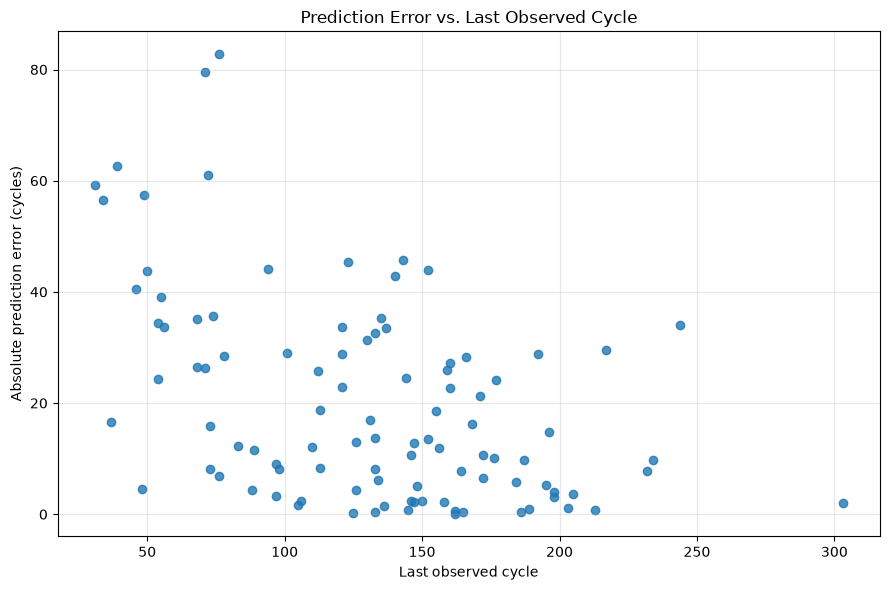

In [47]:
import matplotlib.pyplot as plt
import numpy as np

test_results["signed_error"] = (
    test_results["predicted_RUL"]
    - test_results["actual_RUL"]
)

test_results["absolute_error"] = (
    test_results["signed_error"].abs()
)

# Compare prediction errors with the last observed cycle
plt.figure(figsize=(9, 6))

plt.scatter(
    test_results["last_observed_cycle"],
    test_results["absolute_error"],
    alpha=0.8
)

plt.xlabel("Last observed cycle")
plt.ylabel("Absolute prediction error (cycles)")
plt.title("Prediction Error vs. Last Observed Cycle")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 14. Compare raw and capped target models

In [48]:
from sklearn.ensemble import RandomForestRegressor

rf_capped = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

rf_capped.fit(X_train, y_train_capped)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [49]:
# Use exactly the same test observations and features
X_test_final = test_final[feature_columns]

test_predictions_capped = rf_capped.predict(X_test_final)

capped_results = pd.DataFrame({
    "engine_id": test_final["engine_id"],
    "last_observed_cycle": test_final["cycle"],
    "predicted_RUL": test_predictions_capped,
    "actual_RUL": test_rul.to_numpy()
})

capped_results["signed_error"] = (
    capped_results["predicted_RUL"]
    - capped_results["actual_RUL"]
)

capped_results["absolute_error"] = (
    capped_results["signed_error"].abs()
)

display(capped_results.head(10))

,engine_id,last_observed_cycle,predicted_RUL,actual_RUL,signed_error,absolute_error
0,1,31,123.752321,112,11.752321,11.752321
1,2,49,123.351833,98,25.351833,25.351833
2,3,126,61.119601,69,-7.880399,7.880399
3,4,106,79.852863,82,-2.147137,2.147137
4,5,98,93.636337,91,2.636337,2.636337
5,6,105,85.196815,93,-7.803185,7.803185
6,7,160,106.286399,91,15.286399,15.286399
7,8,166,65.726642,95,-29.273358,29.273358
8,9,55,118.237464,111,7.237464,7.237464
9,10,192,109.685708,96,13.685708,13.685708


In [50]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

comparison = pd.DataFrame({
    "Model": [
        "Random Forest — Raw RUL",
        "Random Forest — Capped RUL"
    ],
    "MAE": [
        mean_absolute_error(
            test_results["actual_RUL"],
            test_results["predicted_RUL"]
        ),
        mean_absolute_error(
            capped_results["actual_RUL"],
            capped_results["predicted_RUL"]
        )
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            test_results["actual_RUL"],
            test_results["predicted_RUL"]
        )),
        np.sqrt(mean_squared_error(
            capped_results["actual_RUL"],
            capped_results["predicted_RUL"]
        ))
    ],
    "Mean Signed Error": [
        test_results["predicted_RUL"].sub(
            test_results["actual_RUL"]
        ).mean(),
        capped_results["predicted_RUL"].sub(
            capped_results["actual_RUL"]
        ).mean()
    ]
})

display(comparison.round(2))

,Model,MAE,RMSE,Mean Signed Error
0,Random Forest — Raw RUL,20.01,27.14,10.66
1,Random Forest — Capped RUL,13.39,17.84,-1.05


## 15. Compare capped models on held-out validation engines

In [51]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Predict capped RUL for the 20 validation engines
val_capped_predictions = rf_capped.predict(
    val_final[feature_columns]
)

val_capped_comparison = pd.DataFrame({
    "engine_id": val_final["engine_id"].to_numpy(),
    "actual_RUL": val_final["true_RUL"].to_numpy(),
    "predicted_RUL": val_capped_predictions
})

val_capped_comparison["signed_error"] = (
    val_capped_comparison["predicted_RUL"]
    - val_capped_comparison["actual_RUL"]
)

val_capped_comparison["absolute_error"] = (
    val_capped_comparison["signed_error"].abs()
)

val_capped_mae = mean_absolute_error(
    val_capped_comparison["actual_RUL"],
    val_capped_comparison["predicted_RUL"]
)

val_capped_rmse = np.sqrt(
    mean_squared_error(
        val_capped_comparison["actual_RUL"],
        val_capped_comparison["predicted_RUL"]
    )
)

val_capped_bias = (
    val_capped_comparison["signed_error"].mean()
)

print(f"Validation MAE: {val_capped_mae:.2f}")
print(f"Validation RMSE: {val_capped_rmse:.2f}")
print(f"Mean signed error: {val_capped_bias:.2f}")

display(
    val_capped_comparison.sort_values(
        "absolute_error",
        ascending=False
    ).head(10)
)

Validation MAE: 13.71
Validation RMSE: 17.07
Mean signed error: 9.98


,engine_id,actual_RUL,predicted_RUL,signed_error,absolute_error
1,77,31,66.590624,35.590624,35.590624
16,46,52,83.400204,31.400204,31.400204
13,31,47,75.719339,28.719339,28.719339
5,74,34,60.235339,26.235339,26.235339
2,45,32,51.045327,19.045327,19.045327
9,1,39,57.781448,18.781448,18.781448
15,11,48,66.037304,18.037304,18.037304
18,84,54,37.345623,-16.654377,16.654377
12,78,47,61.261843,14.261843,14.261843
6,23,34,47.889845,13.889845,13.889845


In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

cutoff_fractions = [0.60, 0.70, 0.80, 0.90]
capped_cutoff_results = []

val_trajectories = temporal_df[
    temporal_df["engine_id"].isin(val_engines)
].copy()

failure_cycles = (
    val_trajectories.groupby("engine_id")["cycle"]
    .max()
    .rename("failure_cycle")
)

val_trajectories = val_trajectories.join(
    failure_cycles,
    on="engine_id"
)

for fraction in cutoff_fractions:

    val_trajectories["cutoff_cycle"] = (
        val_trajectories["failure_cycle"] * fraction
    ).astype(int)

    observed = val_trajectories[
        val_trajectories["cycle"]
        <= val_trajectories["cutoff_cycle"]
    ].copy()

    final_rows = (
        observed.sort_values("cycle")
        .groupby("engine_id")
        .tail(1)
        .copy()
    )

    final_rows["true_RUL"] = (
        final_rows["failure_cycle"] - final_rows["cycle"]
    )

    predictions = rf_capped.predict(
        final_rows[feature_columns]
    )

    actual = final_rows["true_RUL"].to_numpy()

    capped_cutoff_results.append({
        "cutoff_fraction": fraction,
        "engines": final_rows["engine_id"].nunique(),
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predictions)
        ),
        "mean_signed_error": np.mean(predictions - actual)
    })

capped_cutoff_results = pd.DataFrame(capped_cutoff_results)

display(capped_cutoff_results.round(2))

,cutoff_fraction,engines,MAE,RMSE,mean_signed_error
0,0.6,20,17.12,23.27,7.18
1,0.7,20,18.76,23.42,12.05
2,0.8,20,13.71,17.07,9.98
3,0.9,20,7.33,8.83,4.85


## 16. RUL-cap sensitivity experiment

In [53]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

caps = [100, 125, 150]
cap_results = []

# Use the same held-out validation engines and 80% cutoff
val_trajectories = train_df.loc[val_mask].copy()

failure_cycles = (
    val_trajectories.groupby("engine_id")["cycle"]
    .max()
    .rename("failure_cycle")
)

val_trajectories = val_trajectories.join(
    failure_cycles,
    on="engine_id"
)

val_trajectories["cutoff_cycle"] = (
    val_trajectories["failure_cycle"] * 0.8
).astype(int)

val_final_cap = (
    val_trajectories[
        val_trajectories["cycle"]
        <= val_trajectories["cutoff_cycle"]
    ]
    .sort_values("cycle")
    .groupby("engine_id")
    .tail(1)
    .copy()
)

val_final_cap["true_RUL"] = (
    val_final_cap["failure_cycle"] - val_final_cap["cycle"]
)

X_val_cap = val_final_cap[feature_columns]
y_val_cap = val_final_cap["true_RUL"]

# Train using training engines only
X_train_cap = X.loc[train_mask]
y_train_raw_cap = y_raw.loc[train_mask]

for cap in caps:
    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    )

    model.fit(
        X_train_cap,
        y_train_raw_cap.clip(upper=cap)
    )

    predictions = model.predict(X_val_cap)

    cap_results.append({
        "RUL_cap": cap,
        "MAE": mean_absolute_error(y_val_cap, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_val_cap, predictions)
        ),
        "mean_signed_error": np.mean(predictions - y_val_cap)
    })

display(pd.DataFrame(cap_results).round(2))

,RUL_cap,MAE,RMSE,mean_signed_error
0,100,13.76,16.79,9.82
1,125,13.71,17.07,9.98
2,150,13.14,16.38,10.01


In [54]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

caps = [125, 150, 175, 200]
cap_results = []

X_train_cap = X.loc[train_mask]
y_train_raw_cap = y_raw.loc[train_mask]

X_val_cap = val_final[feature_columns]
y_val_cap = val_final["true_RUL"]

for cap in caps:
    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    )

    model.fit(
        X_train_cap,
        y_train_raw_cap.clip(upper=cap)
    )

    predictions = model.predict(X_val_cap)

    cap_results.append({
        "RUL_cap": cap,
        "MAE": mean_absolute_error(y_val_cap, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_val_cap, predictions)
        ),
        "mean_signed_error": np.mean(predictions - y_val_cap)
    })

cap_comparison = pd.DataFrame(cap_results)
display(cap_comparison.round(2))

,RUL_cap,MAE,RMSE,mean_signed_error
0,125,13.71,17.07,9.98
1,150,13.14,16.38,10.01
2,175,13.01,16.76,10.17
3,200,13.06,16.59,9.92


In [55]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

caps = [150, 175]
cutoff_fractions = [0.60, 0.70, 0.80, 0.90]

results = []

# Train only on the training engines
X_train_cap = X.loc[train_mask]
y_train_raw_cap = y_raw.loc[train_mask]

# Build held-out validation trajectories
val_trajectories = train_df.loc[val_mask].copy()

failure_cycles = (
    val_trajectories.groupby("engine_id")["cycle"]
    .max()
    .rename("failure_cycle")
)

val_trajectories = val_trajectories.join(
    failure_cycles,
    on="engine_id"
)

for cap in caps:

    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    )

    model.fit(
        X_train_cap,
        y_train_raw_cap.clip(upper=cap)
    )

    for fraction in cutoff_fractions:

        cutoff_cycle = (
            val_trajectories["failure_cycle"] * fraction
        ).astype(int)

        observed = val_trajectories[
            val_trajectories["cycle"] <= cutoff_cycle
        ].copy()

        final_rows = (
            observed.sort_values("cycle")
            .groupby("engine_id")
            .tail(1)
            .copy()
        )

        final_rows["true_RUL"] = (
            final_rows["failure_cycle"] - final_rows["cycle"]
        )

        predictions = model.predict(
            final_rows[feature_columns]
        )

        actual = final_rows["true_RUL"].to_numpy()

        results.append({
            "RUL_cap": cap,
            "cutoff": fraction,
            "MAE": mean_absolute_error(actual, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(actual, predictions)
            ),
            "mean_signed_error": np.mean(predictions - actual)
        })

cap_cutoff_results = pd.DataFrame(results)

display(
    cap_cutoff_results.round(2)
    .sort_values(["cutoff", "RUL_cap"])
    .reset_index(drop=True)
)

,RUL_cap,cutoff,MAE,RMSE,mean_signed_error
0,150,0.6,20.08,25.74,11.78
1,175,0.6,22.00,27.75,14.16
2,150,0.7,21.08,26.51,14.05
3,175,0.7,20.63,26.21,13.84
4,150,0.8,13.14,16.38,10.01
5,175,0.8,13.01,16.76,10.17
6,150,0.9,7.19,8.46,4.71
7,175,0.9,7.64,9.23,5.16


## 17. Conclusions and next steps

Use the observations below as a working summary. Re-run the relevant cells from a clean kernel before treating any metric as reproducible.

### Findings from this exploration

- The training set contains **20,631 observations from 100 engines**; no missing values or duplicate rows were found in the initial checks.
- Several columns are constant in FD001 and were excluded from the modeling feature list.
- The data split is performed by **engine ID**, keeping validation engines separate from training engines.
- The Random Forest baseline uses 200 trees, `random_state=42`, `n_jobs=-1`, and `min_samples_leaf=2`.
- At the 80% observation cutoff, the raw-target baseline achieved approximately **MAE 13.79** and **RMSE 17.22** on the 20 held-out validation engines.
- A target cap of 150 was the strongest candidate in the cap experiment at that cutoff (**MAE 13.14**, **RMSE 16.38**), but the validation sample is small; treat this as a candidate, not a proven universal optimum.
- Temporal features produced mixed results and did not clearly improve the baseline.
- The official test-set comparison was explored during this notebook. Avoid further model selection using those labels; use validation for future decisions and reserve a final test evaluation for the selected pipeline.

### Next steps

1. Build `02_reproducible_baseline.ipynb` with only the chosen, reproducible pipeline.
2. Move reusable loading, feature, training, and evaluation logic into `src/`.
3. Add tests for RUL construction and data loading.
4. Track experiments and model configuration consistently.
